In [80]:
import pandas as pd
import matplotlib.pyplot as plt

In [74]:
run_name = "tinystories-base-64b"

In [50]:
df = pd.read_json(f"../runs/{run_name}/metrics.jsonl", lines=True)
df

,step,time,train_loss,lr,val_loss
0,10,15.060000,8.469139,0.000167,NaN
1,20,28.660000,6.913788,0.000333,NaN
2,10,15.120000,8.427797,0.000167,NaN
3,20,28.550000,6.843823,0.000333,NaN
4,30,42.050000,5.369480,0.000500,NaN
5,40,55.610000,4.528574,0.000667,NaN
6,50,69.040000,4.006947,0.000833,NaN
7,100,135.700000,3.243624,0.000999,NaN
8,200,273.550000,2.700935,0.000993,NaN
9,300,408.010000,2.429947,0.000979,NaN


In [51]:
train = df[df["train_loss"].notna()]
train

,step,time,train_loss,lr,val_loss
0,10,15.06,8.469139,0.000167,NaN
1,20,28.66,6.913788,0.000333,NaN
2,10,15.12,8.427797,0.000167,NaN
3,20,28.55,6.843823,0.000333,NaN
4,30,42.05,5.369480,0.000500,NaN
5,40,55.61,4.528574,0.000667,NaN
6,50,69.04,4.006947,0.000833,NaN
7,100,135.70,3.243624,0.000999,NaN
8,200,273.55,2.700935,0.000993,NaN
9,300,408.01,2.429947,0.000979,NaN


In [52]:
val = df[df["val_loss"].notna()]
val

,step,time,train_loss,lr,val_loss
12,500,684.657779,NaN,NaN,2.170043
18,1000,1397.788436,NaN,NaN,1.924660
24,1500,2076.806563,NaN,NaN,1.775767
30,2000,2751.078369,NaN,NaN,1.677184
36,2500,3447.125477,NaN,NaN,1.667263


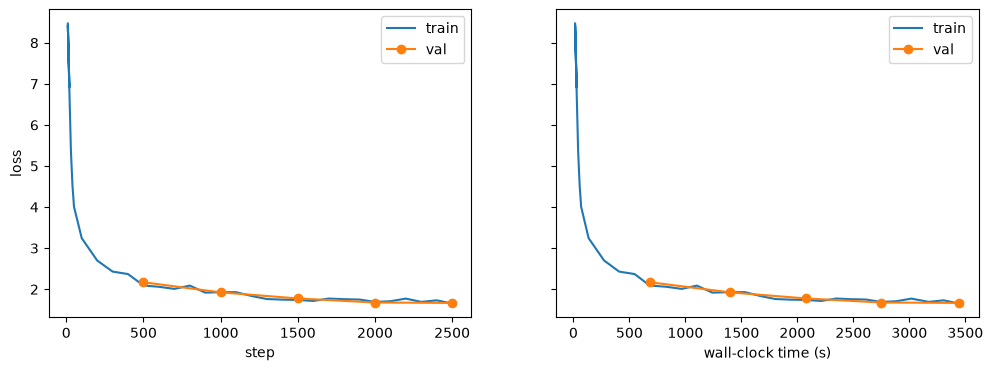

In [53]:
fig, (ax_step, ax_time) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, x in [(ax_step, "step"), (ax_time, "time")]:
    ax.plot(train[x], train["train_loss"], label="train")
    ax.plot(val[x], val["val_loss"], label="val", marker="o")
    ax.set_xlabel("step" if x == "step" else "wall-clock time (s)")
    ax.legend()

ax_step.set_ylabel("loss")
fig.savefig(f"../runs/{run_name}/loss.png", dpi=150, bbox_inches="tight")
plt.show()

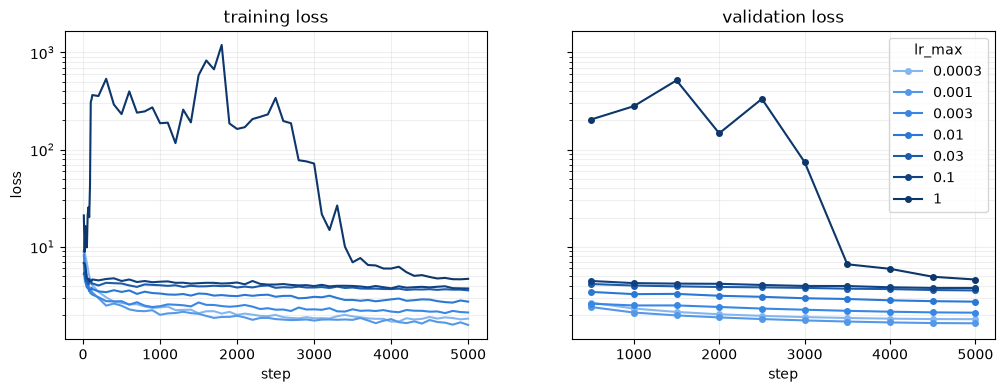

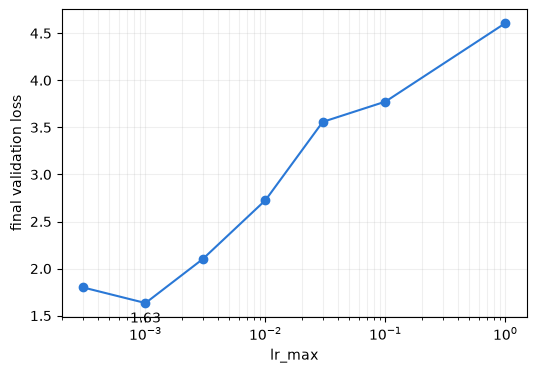

In [81]:
import glob
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

runs_dir = "../runs"
run_names = ["tinystories-base-32b"] + [os.path.basename(p) for p in glob.glob(f"{runs_dir}/tinystories-lr-*")]

runs = []
for run_name in run_names:
    with open(f"{runs_dir}/{run_name}/config.json") as f:
        lr = json.load(f)["optimizer_lr_max"]
    df = pd.read_json(f"{runs_dir}/{run_name}/metrics.jsonl", lines=True)
    runs.append((lr, df))
runs.sort(key=lambda run: run[0])

# One blue ramp: light = low learning rate, dark = high learning rate
ramp = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
colors = [ramp[i] for i in np.linspace(0, len(ramp) - 1, len(runs)).round().astype(int)]

fig, (ax_train, ax_val) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for (lr, df), color in zip(runs, colors):
    train = df[df["train_loss"].notna()]
    val = df[df["val_loss"].notna()]
    ax_train.plot(train["step"], train["train_loss"], color=color, linewidth=1.5, label=f"{lr:g}")
    ax_val.plot(val["step"], val["val_loss"], color=color, linewidth=1.5, marker="o", markersize=4, label=f"{lr:g}")

for ax, title in [(ax_train, "training loss"), (ax_val, "validation loss")]:
    ax.set_yscale("log")
    ax.set_xlabel("step")
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.2)
    # ax.set_ylim(1.4, 10)  # uncomment to zoom in on the runs that converged

ax_train.set_ylabel("loss")
ax_val.legend(title="lr_max")
fig.savefig("../figures/lr_sweep_curves.png", dpi=150, bbox_inches="tight")
plt.show()

final = [(lr, df["val_loss"].dropna().iloc[-1]) for lr, df in runs]
lrs, final_losses = zip(*final)
best_lr, best_loss = min(final, key=lambda run: run[1])

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(lrs, final_losses, color="#2a78d6", linewidth=1.5, marker="o", markersize=6)
ax.annotate(f"{best_loss:.2f}", (best_lr, best_loss), textcoords="offset points", xytext=(0, -14), ha="center")
ax.set_xscale("log")
ax.set_xlabel("lr_max")
ax.set_ylabel("final validation loss")
ax.grid(True, which="both", alpha=0.2)
fig.savefig("../figures/lr_sweep_final.png", dpi=150, bbox_inches="tight")
plt.show()

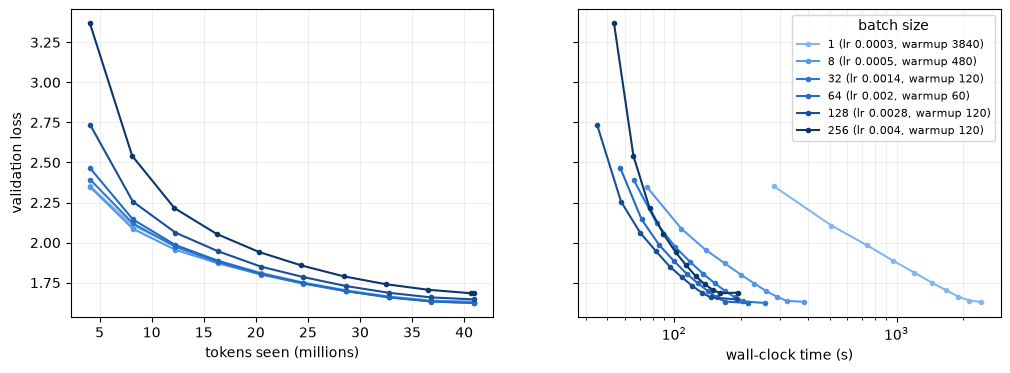

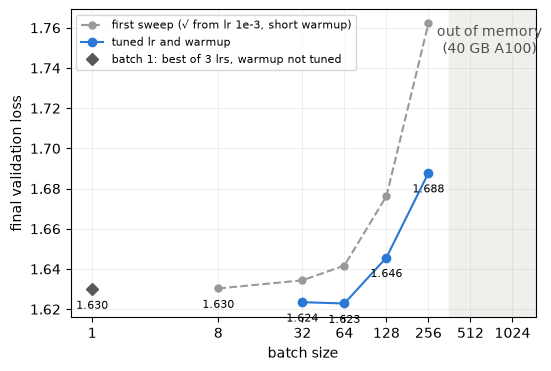

In [82]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

runs_dir = "../runs/a100"
# Best run per batch size (~41M tokens each). Learning rate and warmup were tuned only from batch 32 up;
# batch 1 is the best of three learning rates, batch 8 is its first-sweep run.
run_names = [
    "tinystories-1b-lr-3e-4",
    "tinystories-a100-8b",
    "tinystories-a100-32b-lr-1.4e-3-wu120",
    "tinystories-a100-64b-linear",  # lr 2e-3, warmup 60
    "tinystories-a100-128b-lr-2.8e-3-wu120",
    "tinystories-a100-256b-lr-4e-3-wu120",
]
# First sweep: √ scaling from lr 1e-3 at batch 32, warmup a fixed 2.4% of the steps
first_sweep_names = [
    "tinystories-a100-8b",
    "tinystories-a100-base",
    "tinystories-a100-64b",
    "tinystories-a100-128b",
    "tinystories-a100-256b",
]
batch_1_name = "tinystories-1b-lr-3e-4"
out_of_memory = [512, 1024]


def load_run(run_name):
    with open(f"{runs_dir}/{run_name}/config.json") as f:
        config = json.load(f)
    df = pd.read_json(f"{runs_dir}/{run_name}/metrics.jsonl", lines=True)
    df["tokens"] = df["step"] * config["batch_size"] * config["model_context_length"]
    return config, df


def final_loss(df):
    return df["val_loss"].dropna().iloc[-1]


runs = sorted((load_run(run_name) for run_name in run_names), key=lambda run: run[0]["batch_size"])

# One blue ramp: light = small batch, dark = large batch
ramp = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
colors = [ramp[i] for i in np.linspace(0, len(ramp) - 1, len(runs)).round().astype(int)]

fig, (ax_tokens, ax_time) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for (config, df), color in zip(runs, colors):
    val = df[df["val_loss"].notna()]
    label = f"{config['batch_size']} (lr {config['optimizer_lr_max']:g}, warmup {config['optimizer_warmup_iters']})"
    ax_tokens.plot(val["tokens"] / 1e6, val["val_loss"], color=color, linewidth=1.5, marker="o", markersize=3, label=label)
    ax_time.plot(val["time"], val["val_loss"], color=color, linewidth=1.5, marker="o", markersize=3, label=label)

ax_tokens.set_xlabel("tokens seen (millions)")
ax_time.set_xlabel("wall-clock time (s)")
ax_time.set_xscale("log")
ax_tokens.set_ylabel("validation loss")
for ax in (ax_tokens, ax_time):
    ax.grid(True, which="both", alpha=0.2)
ax_time.legend(title="batch size", fontsize=8)

fig.savefig("../figures/batch_size_curves.png", dpi=150, bbox_inches="tight")
plt.show()

tuned = [(config["batch_size"], final_loss(df)) for config, df in runs if config["batch_size"] >= 32]
first_sweep = sorted((config["batch_size"], final_loss(df)) for config, df in map(load_run, first_sweep_names))
batch_1 = (1, final_loss(load_run(batch_1_name)[1]))

fig, ax = plt.subplots(figsize=(6, 4))
ax.axvspan(360, 1500, color="#f0efec")
ax.text(700, max(loss for _, loss in first_sweep + tuned), "out of memory\n(40 GB A100)", ha="center", va="top", color="#52514e")
ax.plot(*zip(*first_sweep), color="0.6", linestyle="--", linewidth=1.5, marker="o", markersize=5,
        label="first sweep (√ from lr 1e-3, short warmup)")
ax.plot(*zip(*tuned), color="#2a78d6", linewidth=1.5, marker="o", markersize=6, label="tuned lr and warmup")
ax.plot(*batch_1, color="0.35", marker="D", markersize=6, linestyle="none", label="batch 1: best of 3 lrs, warmup not tuned")
for batch_size, loss in tuned + [batch_1, first_sweep[0]]:
    ax.annotate(f"{loss:.3f}", (batch_size, loss), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8)

ticks = [1] + [batch_size for batch_size, _ in first_sweep] + out_of_memory
ax.set_xscale("log", base=2)
ax.set_xticks(ticks, labels=[str(t) for t in ticks])
ax.set_xlim(0.7, 1500)
ax.set_xlabel("batch size")
ax.set_ylabel("final validation loss")
ax.grid(True, which="both", alpha=0.2)
ax.legend(fontsize=8, loc="upper left")

fig.savefig("../figures/batch_size_final.png", dpi=150, bbox_inches="tight")
plt.show()

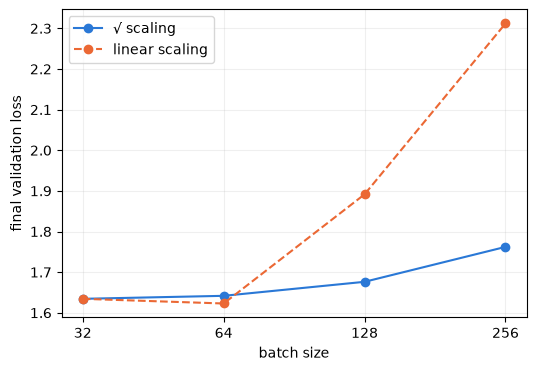

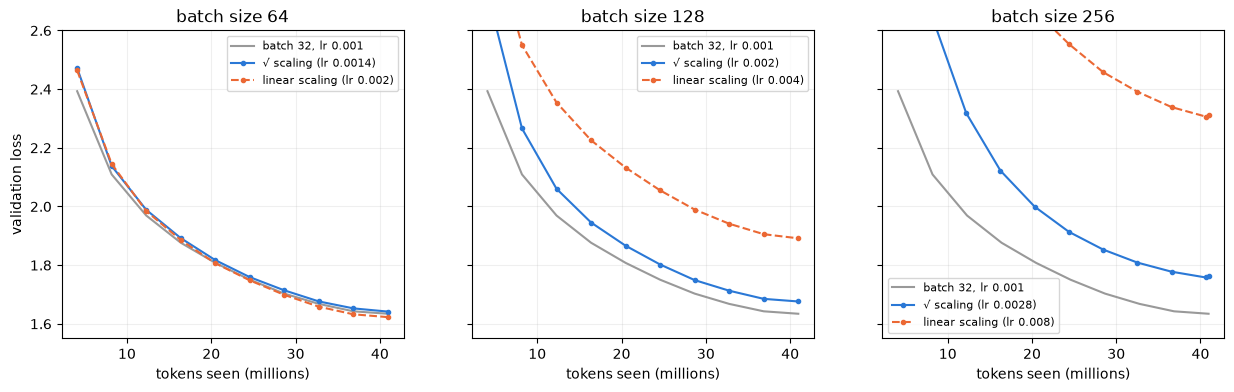

In [83]:
import json

import matplotlib.pyplot as plt
import pandas as pd

runs_dir = "../runs/a100"
batch_sizes = [64, 128, 256]
baseline = "tinystories-a100-base"  # batch 32, lr 1e-3: the starting point of both rules
rules = {
    "√ scaling": ("tinystories-a100-{}b", "#2a78d6", "-"),
    "linear scaling": ("tinystories-a100-{}b-linear", "#eb6834", "--"),
}


def load_val(run_name):
    with open(f"{runs_dir}/{run_name}/config.json") as f:
        config = json.load(f)
    df = pd.read_json(f"{runs_dir}/{run_name}/metrics.jsonl", lines=True)
    df["tokens"] = df["step"] * config["batch_size"] * config["model_context_length"]
    return config, df[df["val_loss"].notna()]

_, base_val = load_val(baseline)

fig, ax = plt.subplots(figsize=(6, 4))
for rule, (pattern, color, style) in rules.items():
    losses = [base_val["val_loss"].iloc[-1]] + [load_val(pattern.format(b))[1]["val_loss"].iloc[-1] for b in batch_sizes]
    ax.plot([32] + batch_sizes, losses, color=color, linestyle=style, linewidth=1.5, marker="o", markersize=6, label=rule)

ax.set_xscale("log", base=2)
ax.set_xticks([32] + batch_sizes, labels=[str(b) for b in [32] + batch_sizes])
ax.set_xlabel("batch size")
ax.set_ylabel("final validation loss")
ax.grid(True, which="both", alpha=0.2)
ax.legend()

fig.savefig("../figures/lr_scaling_final.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, len(batch_sizes), figsize=(15, 4), sharey=True)

for ax, batch_size in zip(axes, batch_sizes):
    ax.plot(base_val["tokens"] / 1e6, base_val["val_loss"], color="0.6", linewidth=1.5, label="batch 32, lr 0.001")
    for rule, (pattern, color, style) in rules.items():
        config, val = load_val(pattern.format(batch_size))
        ax.plot(val["tokens"] / 1e6, val["val_loss"], color=color, linestyle=style, linewidth=1.5,
                marker="o", markersize=3, label=f"{rule} (lr {config['optimizer_lr_max']:g})")
    ax.set_title(f"batch size {batch_size}")
    ax.set_xlabel("tokens seen (millions)")
    ax.set_ylim(1.55, 2.6)  # zoom in on the second half of training, where the runs separate
    ax.grid(True, alpha=0.2)
    ax.legend(fontsize=8)

axes[0].set_ylabel("validation loss")
fig.savefig("../figures/lr_scaling_curves.png", dpi=150, bbox_inches="tight")
plt.show()

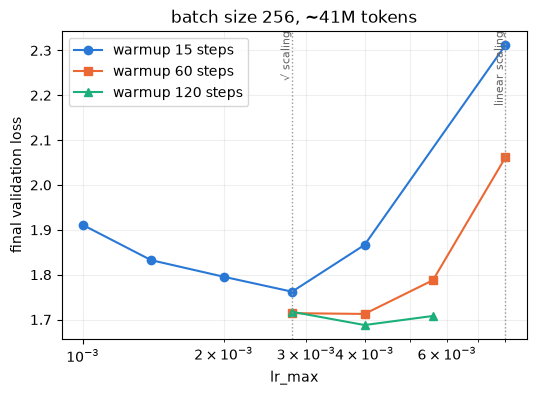

In [84]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

lr_runs_256 = [
    # warmup 15
    "tinystories-a100-256b-lr-1e-3",
    "tinystories-a100-256b-lr-1.4e-3",
    "tinystories-a100-256b-lr-2e-3",
    "tinystories-a100-256b",
    "tinystories-a100-256b-lr-4e-3",
    "tinystories-a100-256b-linear",
    # warmup 60
    "tinystories-a100-256b-lr-2.8e-3-wu60",
    "tinystories-a100-256b-lr-4e-3-wu60",
    "tinystories-a100-256b-lr-5.6e-3",
    "tinystories-a100-256b-lr-8e-3",
    # warmup 120
    "tinystories-a100-256b-lr-2.8e-3-wu120",
    "tinystories-a100-256b-lr-4e-3-wu120",
    "tinystories-a100-256b-lr-5.6e-3-wu120",
]

points = []
for run_name in lr_runs_256:
    config, val = load_val(run_name)
    points.append((config["optimizer_lr_max"], config["optimizer_warmup_iters"], val["val_loss"].iloc[-1]))

fig, ax = plt.subplots(figsize=(6, 4))
for warmup, color, marker in [(15, "#2a78d6", "o"), (60, "#eb6834", "s"), (120, "#1baf7a", "^")]:
    lrs, losses = zip(*sorted((lr, loss) for lr, w, loss in points if w == warmup))
    ax.plot(lrs, losses, color=color, linewidth=1.5, marker=marker, markersize=6, label=f"warmup {warmup} steps")

for lr, name in [(2.8e-3, "√ scaling"), (8e-3, "linear scaling")]:
    ax.axvline(lr, color="0.6", linestyle=":", linewidth=1)
    ax.text(lr, ax.get_ylim()[1], name, rotation=90, ha="right", va="top", fontsize=8, color="0.4")

ax.set_xscale("log")
ax.set_xlabel("lr_max")
ax.set_ylabel("final validation loss")
ax.set_title("batch size 256, ~41M tokens")
ax.grid(True, which="both", alpha=0.2)
ax.legend()

fig.savefig("../figures/lr_sweep_256.png", dpi=150, bbox_inches="tight")
plt.show()

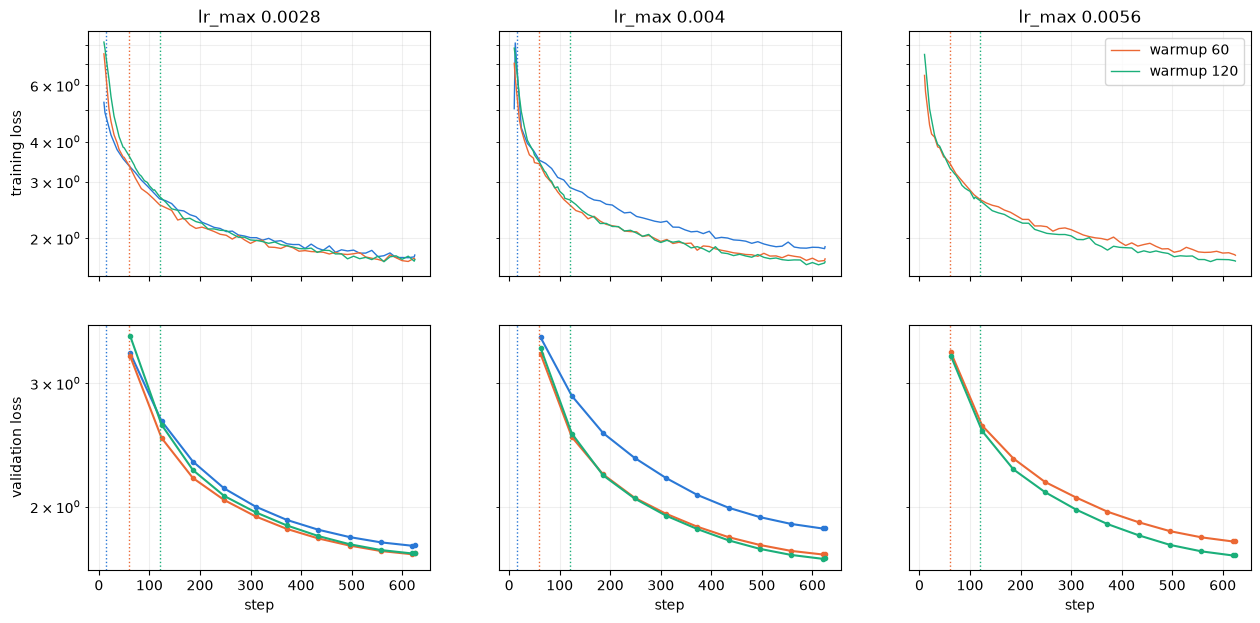

In [85]:
warmup_runs = {  # lr_max -> {warmup steps: run name}
    2.8e-3: {15: "tinystories-a100-256b", 60: "tinystories-a100-256b-lr-2.8e-3-wu60", 120: "tinystories-a100-256b-lr-2.8e-3-wu120"},
    4e-3: {15: "tinystories-a100-256b-lr-4e-3", 60: "tinystories-a100-256b-lr-4e-3-wu60", 120: "tinystories-a100-256b-lr-4e-3-wu120"},
    5.6e-3: {60: "tinystories-a100-256b-lr-5.6e-3", 120: "tinystories-a100-256b-lr-5.6e-3-wu120"},
}
warmup_colors = {15: "#2a78d6", 60: "#eb6834", 120: "#1baf7a"}

fig, axes = plt.subplots(2, len(warmup_runs), figsize=(15, 7), sharex=True, sharey="row")
for col, (lr, runs) in enumerate(warmup_runs.items()):
    ax_train, ax_val = axes[0, col], axes[1, col]
    for warmup, run_name in runs.items():
        df = pd.read_json(f"{runs_dir}/{run_name}/metrics.jsonl", lines=True)
        train = df[df["train_loss"].notna()]
        val = df[df["val_loss"].notna()]
        color = warmup_colors[warmup]
        ax_train.plot(train["step"], train["train_loss"], color=color, linewidth=1, label=f"warmup {warmup}")
        ax_val.plot(val["step"], val["val_loss"], color=color, linewidth=1.5, marker="o", markersize=3, label=f"warmup {warmup}")
        for ax in (ax_train, ax_val):
            ax.axvline(warmup, color=color, linestyle=":", linewidth=1)
    ax_train.set_title(f"lr_max {lr:g}")
    ax_val.set_xlabel("step")
    for ax in (ax_train, ax_val):
        ax.set_yscale("log")
        ax.grid(True, which="both", alpha=0.2)

axes[0, 0].set_ylabel("training loss")
axes[1, 0].set_ylabel("validation loss")
axes[0, -1].legend()
fig.savefig("../figures/warmup_curves.png", dpi=150, bbox_inches="tight")
plt.show()

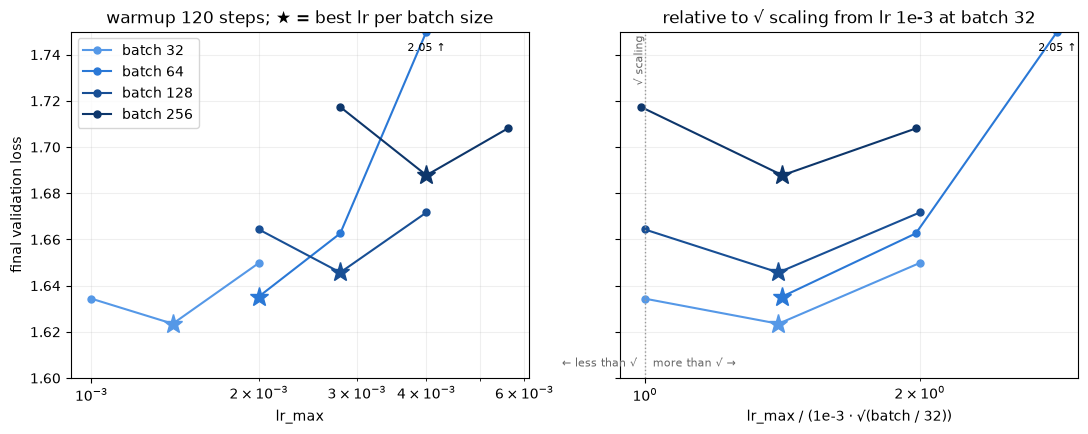

In [86]:
# Learning rate sweeps with warmup 120, one line per batch size (~41M tokens each).
# Uses load_run, final_loss and ramp from the batch size cell.
lr_sweeps = {
    32: ["tinystories-a100-base", "tinystories-a100-32b-lr-1.4e-3-wu120", "tinystories-a100-32b-lr-2e-3-wu120"],
    64: ["tinystories-a100-64b-lr-2e-3-wu120", "tinystories-a100-64b-lr-2.8e-3-wu120", "tinystories-a100-64b-lr-4e-3-wu120"],
    128: ["tinystories-a100-128b-lr-2e-3-wu120", "tinystories-a100-128b-lr-2.8e-3-wu120", "tinystories-a100-128b-lr-4e-3-wu120"],
    256: ["tinystories-a100-256b-lr-2.8e-3-wu120", "tinystories-a100-256b-lr-4e-3-wu120", "tinystories-a100-256b-lr-5.6e-3-wu120"],
}
base_lr, base_batch_size = 1e-3, 32  # the √ rule of the first sweep: lr = 1e-3 · √(batch / 32)
top = 1.75  # zoom in on the minima; points above it are drawn at the edge with their value
sweep_colors = [ramp[i] for i in np.linspace(2, len(ramp) - 1, len(lr_sweeps)).round().astype(int)]

fig, (ax_lr, ax_ratio) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for (batch_size, names), color in zip(lr_sweeps.items(), sweep_colors):
    sqrt_lr = base_lr * (batch_size / base_batch_size) ** 0.5
    points = sorted((config["optimizer_lr_max"], final_loss(df)) for config, df in map(load_run, names))
    best_lr, best_loss = min(points, key=lambda point: point[1])
    for ax, scale in [(ax_lr, 1), (ax_ratio, sqrt_lr)]:
        xs = [lr / scale for lr, _ in points]
        ax.plot(xs, [min(loss, top) for _, loss in points], color=color, linewidth=1.5, marker="o", markersize=5,
                label=f"batch {batch_size}")
        ax.plot(best_lr / scale, best_loss, color=color, marker="*", markersize=14, linestyle="none")
        for x, (_, loss) in zip(xs, points):
            if loss > top:
                ax.annotate(f"{loss:.2f} ↑", (x, top), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=8)

ax_ratio.axvline(1, color="0.6", linestyle=":", linewidth=1)
ax_ratio.text(1, top, "√ scaling ", rotation=90, ha="right", va="top", fontsize=8, color="0.4")
ax_ratio.text(0.98, 1.605, "← less than √", ha="right", fontsize=8, color="0.4")
ax_ratio.text(1.02, 1.605, "more than √ →", ha="left", fontsize=8, color="0.4")

ax_lr.set_xlabel("lr_max")
ax_ratio.set_xlabel("lr_max / (1e-3 · √(batch / 32))")
for ax in (ax_lr, ax_ratio):
    ax.set_xscale("log")
    ax.grid(True, which="both", alpha=0.2)
ax_lr.set_ylim(1.6, top)
ax_lr.set_ylabel("final validation loss")
ax_lr.set_title("warmup 120 steps; ★ = best lr per batch size")
ax_ratio.set_title("relative to √ scaling from lr 1e-3 at batch 32")
ax_lr.legend()

fig.savefig("../figures/lr_vs_batch_size.png", dpi=150, bbox_inches="tight")
plt.show()

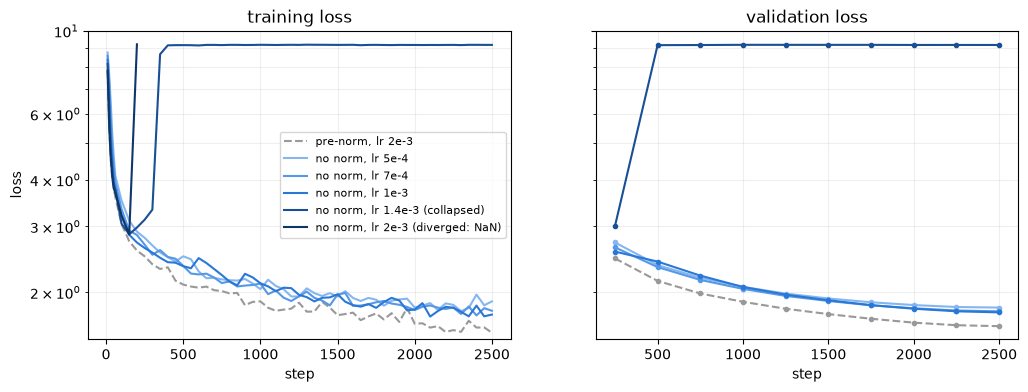

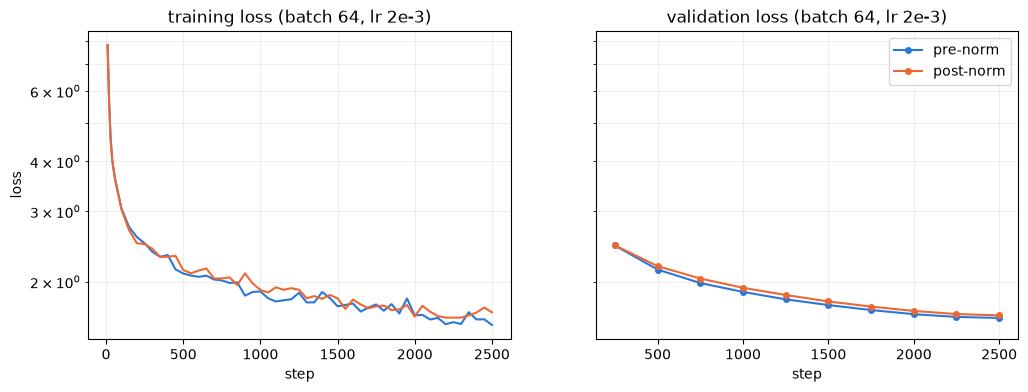

In [87]:
# Layer norm ablations at batch 64, warmup 60, ~41M tokens, compared to the pre-norm baseline (lr 2e-3).
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

runs_dir = "../runs/a100"
pre_norm = "tinystories-a100-64b-linear"  # pre-norm, lr 2e-3, warmup 60
no_norm_runs = {lr: f"tinystories-a100-64b-no-rmsnorm-blocks-lr-{lr}" for lr in ["5e-4", "7e-4", "1e-3", "1.4e-3", "2e-3"]}
post_norm = "tinystories-a100-64b-post-norm-lr-2e-3"


def load_curves(run_name):
    df = pd.read_json(f"{runs_dir}/{run_name}/metrics.jsonl", lines=True)
    train = df[df["lr"].notna()]  # training lines log an lr, validation lines don't
    val = df[df["lr"].isna()]
    if train["train_loss"].isna().any():
        status = " (diverged: NaN)"
    elif train["train_loss"].iloc[-1] > 8:  # ~ln(10000): back to guessing uniformly
        status = " (collapsed)"
    else:
        status = ""
    return train[train["train_loss"].notna()], val[val["val_loss"].notna()], status


# 1. No RMSNorm in the blocks: learning rate sweep
ramp = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
colors = [ramp[i] for i in np.linspace(0, len(ramp) - 1, len(no_norm_runs)).round().astype(int)]

fig, (ax_train, ax_val) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
base_train, base_val, _ = load_curves(pre_norm)
ax_train.plot(base_train["step"], base_train["train_loss"], color="0.6", linestyle="--", linewidth=1.5, label="pre-norm, lr 2e-3")
ax_val.plot(base_val["step"], base_val["val_loss"], color="0.6", linestyle="--", linewidth=1.5, marker="o", markersize=3, label="pre-norm, lr 2e-3")
for (lr, run_name), color in zip(no_norm_runs.items(), colors):
    train, val, status = load_curves(run_name)  # a diverged run's line ends where the loss became NaN
    ax_train.plot(train["step"], train["train_loss"], color=color, linewidth=1.5, label=f"no norm, lr {lr}{status}")
    ax_val.plot(val["step"], val["val_loss"], color=color, linewidth=1.5, marker="o", markersize=3, label=f"no norm, lr {lr}{status}")

for ax, title in [(ax_train, "training loss"), (ax_val, "validation loss")]:
    ax.set_yscale("log")
    ax.set_ylim(1.5, 10)
    ax.set_xlabel("step")
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.2)
ax_train.set_ylabel("loss")
ax_train.legend(fontsize=8)

fig.savefig("../figures/no_rmsnorm_lr_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Post-norm vs pre-norm, same settings
fig, (ax_train, ax_val) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for run_name, label, color in [(pre_norm, "pre-norm", "#2a78d6"), (post_norm, "post-norm", "#eb6834")]:
    train, val, _ = load_curves(run_name)
    ax_train.plot(train["step"], train["train_loss"], color=color, linewidth=1.5, label=label)
    ax_val.plot(val["step"], val["val_loss"], color=color, linewidth=1.5, marker="o", markersize=4, label=label)

for ax, title in [(ax_train, "training loss"), (ax_val, "validation loss")]:
    ax.set_yscale("log")
    ax.set_xlabel("step")
    ax.set_title(f"{title} (batch 64, lr 2e-3)")
    ax.grid(True, which="both", alpha=0.2)
ax_train.set_ylabel("loss")
ax_val.legend()

fig.savefig("../figures/post_norm_vs_pre_norm.png", dpi=150, bbox_inches="tight")
plt.show()